# KNN Algorithm 

In [2]:
%pip install opencv-python scikit-image

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
    --------------------------------------- 1.0/44.0 MB 11.9 MB/s eta 0:00:04
   --- ------------------------------------ 3.4/44.0 MB 11.9 MB/s eta 0:00:04
   ----- ---------------------------------- 6.0/44.0 MB 11.9 MB/s eta 0:00:04
   ------- -------------------------------- 8.4/44.0 MB 11.8 MB/s eta 0:00:04
   --------- ------------------------------ 10.7/44.0 MB 11.9 MB/s eta 0:00:03
   ------------ --------------------------- 13.4/44.0 MB 11.7 MB/s eta 0:00:03
   -------------- ------------------------- 15.7/44.0 MB 11.7 MB/s eta 0:00:03
   ---------------- ----------------------- 18.4/44.0 MB 11.7 MB/s eta 0:00:03
   ------------------- -------------------- 21.0/44.0 MB 11.8 MB/s eta 0:00:02
   --------------------- ------------------ 23.6/44.0 MB 11.7 MB/s eta 0:00:02
   ----------------------- ---------------- 26.0/44.0 MB 11.7 MB/s


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import cv2
from skimage.feature import hog

print("OpenCV version:", cv2.__version__)
print("HOG imported successfully!")

OpenCV version: 5.0.0
HOG imported successfully!


In [3]:
import os
import numpy as np
import pandas as pd

In [4]:
DATASET_PATH = r"C:\Users\utkri\Downloads\archive (2)\IDC_regular_ps50_idx5"

if os.path.exists(DATASET_PATH):
    print("Dataset path verified successfully!")
else:
    print("Dataset path not found. Please check the path.")

Dataset path verified successfully!


In [5]:
# Initialize lists
image_paths = []
labels = []
patient_ids = []

# Load images from patient folders
for patient in os.listdir(DATASET_PATH):

    patient_path = os.path.join(DATASET_PATH, patient)

    if not os.path.isdir(patient_path):
        continue

    for label in ["0", "1"]:

        class_path = os.path.join(patient_path, label)

        if not os.path.isdir(class_path):
            continue

        for image_name in os.listdir(class_path):

            if image_name.lower().endswith(".png"):

                image_path = os.path.join(class_path, image_name)

                image_paths.append(image_path)
                labels.append(int(label))
                patient_ids.append(patient)

# Convert lists into NumPy arrays
image_paths = np.array(image_paths)
labels = np.array(labels)
patient_ids = np.array(patient_ids)

# Dataset summary
print("Dataset Loaded Successfully!")
print("--------------------------------")
print("Total Images:", len(image_paths))
print("Non-Cancerous Images (0):", np.sum(labels == 0))
print("Cancerous Images (1):", np.sum(labels == 1))
print("Total Patients:", len(np.unique(patient_ids)))

Dataset Loaded Successfully!
--------------------------------
Total Images: 277524
Non-Cancerous Images (0): 198738
Cancerous Images (1): 78786
Total Patients: 279


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

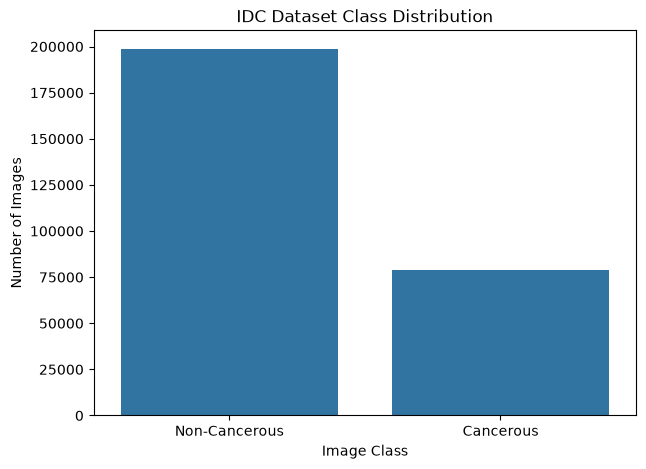

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(x=labels)

plt.xticks([0, 1], ["Non-Cancerous", "Cancerous"])
plt.title("IDC Dataset Class Distribution")
plt.xlabel("Image Class")
plt.ylabel("Number of Images")

plt.show()

# Visualize Sample Histopathology Images

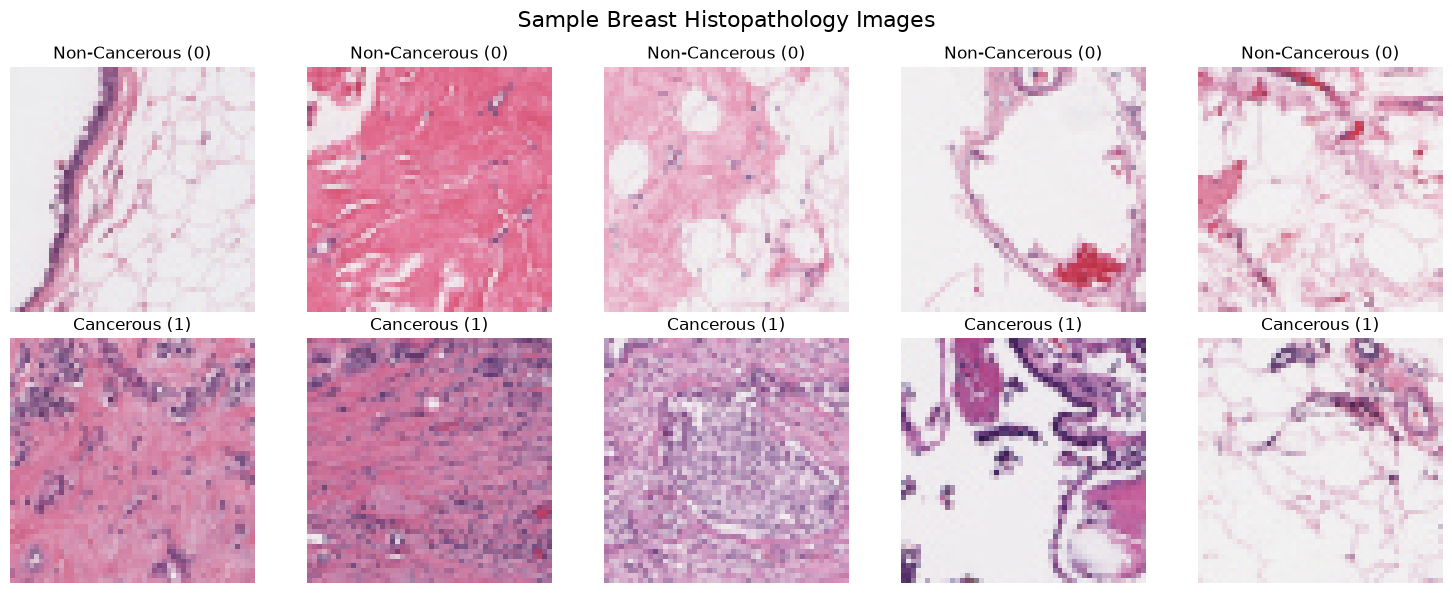

In [9]:
from PIL import Image
import random

# Select 5 images from each class
class_0_indices = np.where(labels == 0)[0]
class_1_indices = np.where(labels == 1)[0]

sample_0 = random.sample(list(class_0_indices), 5)
sample_1 = random.sample(list(class_1_indices), 5)

# Plot sample images
plt.figure(figsize=(15, 6))

for i, idx in enumerate(sample_0 + sample_1):

    image = Image.open(image_paths[idx])

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)

    if labels[idx] == 0:
        plt.title("Non-Cancerous (0)")
    else:
        plt.title("Cancerous (1)")

    plt.axis("off")

plt.suptitle("Sample Breast Histopathology Images", fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import GroupShuffleSplit

# First split: 80% training pool and 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(image_paths, labels, patient_ids)
)

X_train_paths = image_paths[train_idx]
y_train = labels[train_idx]
train_groups = patient_ids[train_idx]

X_test_paths = image_paths[test_idx]
y_test = labels[test_idx]

# Second split: 15% of training pool for validation
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

new_train_idx, val_idx = next(
    splitter_val.split(
        X_train_paths,
        y_train,
        train_groups
    )
)

X_train_final = X_train_paths[new_train_idx]
y_train_final = y_train[new_train_idx]

X_val = X_train_paths[val_idx]
y_val = y_train[val_idx]

# Check patient overlap
train_patients = set(train_groups[new_train_idx])
val_patients = set(train_groups[val_idx])
test_patients = set(patient_ids[test_idx])

print("TRAINING IMAGES:", len(X_train_final))
print("VALIDATION IMAGES:", len(X_val))
print("TESTING IMAGES:", len(X_test_paths))

print("\nTRAINING PATIENTS:", len(train_patients))
print("VALIDATION PATIENTS:", len(val_patients))
print("TESTING PATIENTS:", len(test_patients))

print("\nPatient Overlap (Train/Validation):",
      len(train_patients & val_patients))

print("Patient Overlap (Train/Test):",
      len(train_patients & test_patients))

print("Patient Overlap (Validation/Test):",
      len(val_patients & test_patients))

TRAINING IMAGES: 181549
VALIDATION IMAGES: 38484
TESTING IMAGES: 57491

TRAINING PATIENTS: 189
VALIDATION PATIENTS: 34
TESTING PATIENTS: 56

Patient Overlap (Train/Validation): 0
Patient Overlap (Train/Test): 0
Patient Overlap (Validation/Test): 0


In [11]:
# Step 5: Balanced Training Dataset

import numpy as np

# Set samples per class
SAMPLES_PER_CLASS = 2000

# Find indices of both classes
class_0_indices = np.where(y_train_final == 0)[0]
class_1_indices = np.where(y_train_final == 1)[0]

# Check available samples
print("Available Class 0:", len(class_0_indices))
print("Available Class 1:", len(class_1_indices))

# Select balanced samples
rng = np.random.default_rng(42)

selected_0 = rng.choice(
    class_0_indices,
    min(SAMPLES_PER_CLASS, len(class_0_indices)),
    replace=False
)

selected_1 = rng.choice(
    class_1_indices,
    min(SAMPLES_PER_CLASS, len(class_1_indices)),
    replace=False
)

# Combine and shuffle
balanced_indices = np.concatenate([selected_0, selected_1])
rng.shuffle(balanced_indices)

# Create balanced training data
X_train_balanced = X_train_final[balanced_indices]
y_train_balanced = y_train_final[balanced_indices]

# Display results
print("\nBalanced Training Dataset Created!")
print("Total Training Images:", len(X_train_balanced))
print("Non-Cancerous:", np.sum(y_train_balanced == 0))
print("Cancerous:", np.sum(y_train_balanced == 1))

Available Class 0: 129664
Available Class 1: 51885

Balanced Training Dataset Created!
Total Training Images: 4000
Non-Cancerous: 2000
Cancerous: 2000


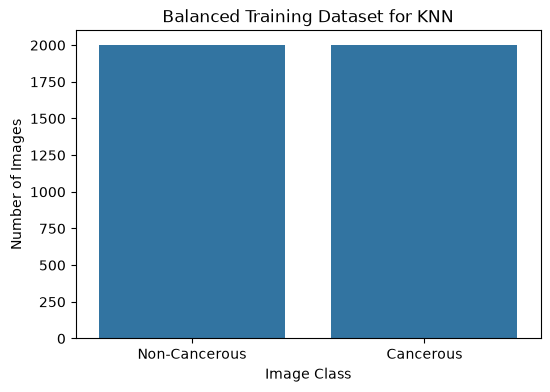

In [12]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y_train_balanced)

plt.xticks(
    [0, 1],
    ["Non-Cancerous", "Cancerous"]
)

plt.title("Balanced Training Dataset for KNN")
plt.xlabel("Image Class")
plt.ylabel("Number of Images")

plt.show()

In [13]:
from skimage.feature import hog
import cv2

def extract_hog_features(image_path):

    # Read image
    image = cv2.imread(image_path)

    # Convert RGB image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Extract HOG features
    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features

print("HOG feature extraction function created successfully!")

HOG feature extraction function created successfully!


In [15]:
import cv2
import numpy as np
from skimage.feature import hog

def extract_hog_features(image_path):

    # Read image
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize image
    gray = cv2.resize(gray, (64, 64))

    # Extract HOG features
    features = hog(
        gray.astype(np.float32),
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    return features

print("Updated HOG function is ready!")

Updated HOG function is ready!


In [16]:
X_train_features = np.array([
    extract_hog_features(path)
    for path in X_train_balanced
])

print("HOG Feature Extraction Completed!")
print("Training Feature Shape:", X_train_features.shape)

HOG Feature Extraction Completed!
Training Feature Shape: (4000, 1764)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:

# ==========================================
# COMPLETE KNN DATA PREPARATION
# ==========================================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# 1. Dataset Path
DATASET_PATH = r"C:\Users\utkri\Downloads\archive (2)\IDC_regular_ps50_idx5"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError("Dataset path not found!")

# 2. Load Dataset
image_paths = []
labels = []
patient_ids = []

for patient in os.listdir(DATASET_PATH):

    patient_path = os.path.join(DATASET_PATH, patient)

    if not os.path.isdir(patient_path):
        continue

    for label in ["0", "1"]:

        class_path = os.path.join(patient_path, label)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):

            if filename.lower().endswith(".png"):

                image_paths.append(os.path.join(class_path, filename))
                labels.append(int(label))
                patient_ids.append(patient)

image_paths = np.array(image_paths)
labels = np.array(labels)
patient_ids = np.array(patient_ids)

print("Dataset Loaded:", len(image_paths))
print("Class 0:", np.sum(labels == 0))
print("Class 1:", np.sum(labels == 1))

# 3. Patient-wise Train/Test Split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(image_paths, labels, patient_ids)
)

X_train_paths = image_paths[train_idx]
y_train = labels[train_idx]
train_groups = patient_ids[train_idx]

X_test_paths = image_paths[test_idx]
y_test = labels[test_idx]

# 4. Patient-wise Validation Split
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

new_train_idx, val_idx = next(
    splitter_val.split(X_train_paths, y_train, train_groups)
)

X_train_final = X_train_paths[new_train_idx]
y_train_final = y_train[new_train_idx]

X_val_paths = X_train_paths[val_idx]
y_val_all = y_train[val_idx]

# 5. Balanced Training Sample
rng = np.random.default_rng(42)

class_0 = np.where(y_train_final == 0)[0]
class_1 = np.where(y_train_final == 1)[0]

n_train = min(2000, len(class_0), len(class_1))

selected_0 = rng.choice(class_0, n_train, replace=False)
selected_1 = rng.choice(class_1, n_train, replace=False)

train_selected = np.concatenate([selected_0, selected_1])
rng.shuffle(train_selected)

X_train_balanced = X_train_final[train_selected]
y_train_balanced = y_train_final[train_selected]

# 6. Balanced Validation and Test Samples
def balanced_sample(paths, targets, samples=1000):

    rng_local = np.random.default_rng(42)

    idx_0 = np.where(targets == 0)[0]
    idx_1 = np.where(targets == 1)[0]

    n = min(samples, len(idx_0), len(idx_1))

    chosen = np.concatenate([
        rng_local.choice(idx_0, n, replace=False),
        rng_local.choice(idx_1, n, replace=False)
    ])

    rng_local.shuffle(chosen)

    return paths[chosen], targets[chosen]

X_val, y_val = balanced_sample(
    X_val_paths, y_val_all
)

X_test_sample, y_test_sample = balanced_sample(
    X_test_paths, y_test
)

# 7. HOG Feature Extraction Function
def extract_hog_features(image_path):

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (64, 64))

    features = hog(
        gray.astype(np.float32),
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features

# 8. Extract Training Features
print("\nExtracting Training HOG Features...")

X_train_features = np.array([
    extract_hog_features(path)
    for path in X_train_balanced
])

# 9. Extract Validation Features
print("Extracting Validation HOG Features...")

X_val_features = np.array([
    extract_hog_features(path)
    for path in X_val
])

# 10. Extract Test Features
print("Extracting Test HOG Features...")

X_test_features = np.array([
    extract_hog_features(path)
    for path in X_test_sample
])

# 11. Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_features)
X_val_scaled = scaler.transform(X_val_features)
X_test_scaled = scaler.transform(X_test_features)

# 12. Final Summary
print("\n========== DATA PREPARATION COMPLETE ==========")

print("Training Shape:", X_train_scaled.shape)
print("Validation Shape:", X_val_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

print("\nTraining Classes:", np.unique(y_train_balanced, return_counts=True))
print("Validation Classes:", np.unique(y_val, return_counts=True))
print("Testing Classes:", np.unique(y_test_sample, return_counts=True))

print("\nAll features extracted and scaled successfully!")


Dataset Loaded: 277524
Class 0: 198738
Class 1: 78786

Extracting Training HOG Features...
Extracting Validation HOG Features...
Extracting Test HOG Features...

========== DATA PREPARATION COMPLETE ==========
Training Shape: (4000, 1764)
Validation Shape: (2000, 1764)
Testing Shape: (2000, 1764)

Training Classes: (array([0, 1]), array([2000, 2000]))
Validation Classes: (array([0, 1]), array([1000, 1000]))
Testing Classes: (array([0, 1]), array([1000, 1000]))

All features extracted and scaled successfully!


In [6]:

# Step 9: KNN Model Training

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

k_values = [3, 5, 7, 9]

results = []

for k in k_values:

    print(f"\nTraining KNN with K = {k}")

    knn_model = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="euclidean",
        n_jobs=-1
    )

    # Train model
    knn_model.fit(X_train_scaled, y_train_balanced)

    # Validation prediction
    y_val_pred = knn_model.predict(X_val_scaled)

    # Calculate metrics
    accuracy = accuracy_score(y_val, y_val_pred)
    precision = precision_score(y_val, y_val_pred)
    recall = recall_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)

    results.append({
        "K": k,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

# Display comparison
results_df = pd.DataFrame(results)

print("\nKNN MODEL COMPARISON")
display(results_df)



Training KNN with K = 3
Accuracy: 0.5335
Precision: 0.5191
Recall: 0.911
F1-Score: 0.6613

Training KNN with K = 5
Accuracy: 0.532
Precision: 0.5175
Recall: 0.946
F1-Score: 0.669

Training KNN with K = 7
Accuracy: 0.5335
Precision: 0.5181
Recall: 0.959
F1-Score: 0.6727

Training KNN with K = 9
Accuracy: 0.529
Precision: 0.5155
Recall: 0.965
F1-Score: 0.672

KNN MODEL COMPARISON


,K,Accuracy,Precision,Recall,F1-Score
0,3,0.5335,0.519088,0.911,0.661343
1,5,0.5320,0.517505,0.946,0.669024
2,7,0.5335,0.518098,0.959,0.672746
3,9,0.5290,0.515491,0.965,0.672006


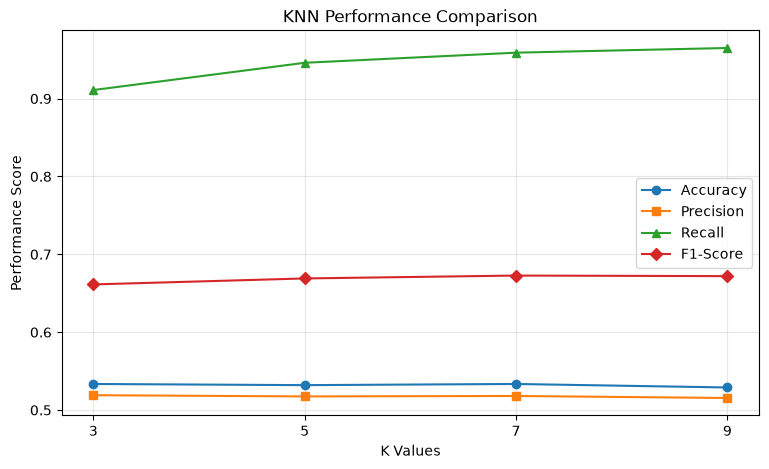

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(results_df["K"], results_df["Accuracy"],
         marker="o", label="Accuracy")

plt.plot(results_df["K"], results_df["Precision"],
         marker="s", label="Precision")

plt.plot(results_df["K"], results_df["Recall"],
         marker="^", label="Recall")

plt.plot(results_df["K"], results_df["F1-Score"],
         marker="D", label="F1-Score")

plt.xlabel("K Values")
plt.ylabel("Performance Score")
plt.title("KNN Performance Comparison")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
# Select best K value
best_k = int(results_df.loc[
    results_df["F1-Score"].idxmax(), "K"
])

print("Best K Value:", best_k)

# Train final KNN model
best_knn_model = KNeighborsClassifier(
    n_neighbors=best_k,
    weights="distance",
    metric="euclidean",
    n_jobs=-1
)

best_knn_model.fit(X_train_scaled, y_train_balanced)

print("Best KNN Model Trained Successfully!")

Best K Value: 7
Best KNN Model Trained Successfully!


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [11]:
# Predict test data
y_test_pred = best_knn_model.predict(X_test_scaled)

y_test_prob = best_knn_model.predict_proba(
    X_test_scaled
)[:, 1]

# Evaluation metrics
print("KNN TEST RESULTS")
print("-----------------------------")

print("Accuracy:", accuracy_score(y_test_sample, y_test_pred))
print("Precision:", precision_score(y_test_sample, y_test_pred))
print("Recall:", recall_score(y_test_sample, y_test_pred))
print("F1-Score:", f1_score(y_test_sample, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test_sample, y_test_prob))

print("\nClassification Report:")
print(classification_report(
    y_test_sample,
    y_test_pred,
    target_names=["Non-Cancerous", "Cancerous"]
))

KNN TEST RESULTS
-----------------------------
Accuracy: 0.5315
Precision: 0.5166931637519873
Recall: 0.975
F1-Score: 0.6754416349151369
ROC-AUC: 0.592644

Classification Report:
               precision    recall  f1-score   support

Non-Cancerous       0.78      0.09      0.16      1000
    Cancerous       0.52      0.97      0.68      1000

     accuracy                           0.53      2000
    macro avg       0.65      0.53      0.42      2000
 weighted avg       0.65      0.53      0.42      2000



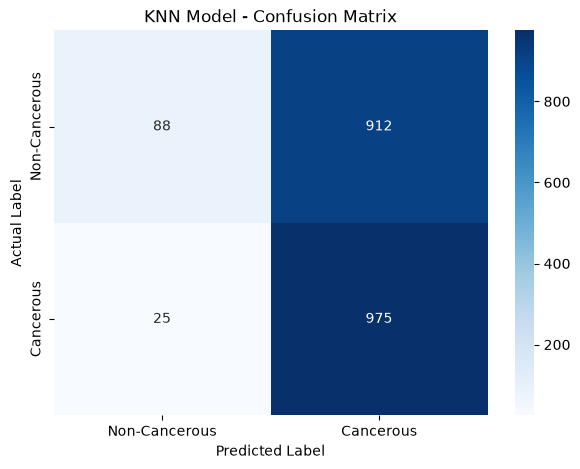

In [12]:
# KNN Confusion Matrix

cm = confusion_matrix(y_test_sample, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Cancerous", "Cancerous"],
    yticklabels=["Non-Cancerous", "Cancerous"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("KNN Model - Confusion Matrix")

plt.savefig("KNN_Confusion_Matrix.png", dpi=300)
plt.show() 

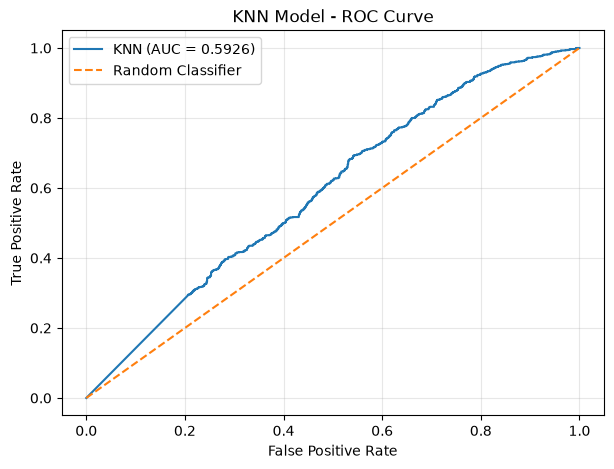

ROC-AUC Score: 0.5926


In [13]:
# KNN ROC Curve

fpr, tpr, thresholds = roc_curve(
    y_test_sample,
    y_test_prob
)

auc_score = roc_auc_score(
    y_test_sample,
    y_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"KNN (AUC = {auc_score:.4f})"
)

plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN Model - ROC Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig("KNN_ROC_Curve.png", dpi=300)
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

In [14]:
import joblib

joblib.dump(best_knn_model, "best_knn_model.pkl")
joblib.dump(scaler, "knn_scaler.pkl")

print("KNN Model and Scaler Saved Successfully!")

KNN Model and Scaler Saved Successfully!


In [15]:
results_df.to_csv("KNN_K_Comparison.csv", index=False)

final_results = pd.DataFrame([{
    "Best K": best_k,
    "Accuracy": accuracy_score(y_test_sample, y_test_pred),
    "Precision": precision_score(y_test_sample, y_test_pred),
    "Recall": recall_score(y_test_sample, y_test_pred),
    "F1 Score": f1_score(y_test_sample, y_test_pred),
    "ROC AUC": roc_auc_score(y_test_sample, y_test_prob)
}])

final_results.to_csv("KNN_Final_Results.csv", index=False)

print("All experimental results saved!")

All experimental results saved!
